# 13b — Cross-dataset test: new cameras, new rooms, new people

**Question:** *do our detectors still work with a camera, a room and people they have never seen?*

- **Test A (no retraining):** learn on the **70 URFD videos**, then test on URFD camera 1 (ceiling), GMDCSA-24 and CAUCAFall.
- **Test B (leave one dataset out):** learn on **two datasets**, test on the **third**, which is never seen.

In both, every **threshold** is chosen on the training datasets only, never on the test dataset.

**Methods** (the best ones of our notebooks): HOG + KNN (04), colour HSV + SVM (06), MobileNetV2 (11), LSTM and GNN on skeletons (12), and the rules of the state machine (10).
MobileNetV2 and ResNet50 were equally good in notebook 11 (0.689 and 0.671, the gap is smaller than the spread between starts): we keep the **10 times smaller** one.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"                # needed for repeatable results on the GPU
from pathlib import Path
import io, pickle, time
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torchvision import models
from skimage.feature import hog
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import roc_auc_score
from joblib import Parallel, delayed

PROC = Path("..") / "data" / "processed"
NEW, CROSS = PROC / "new", PROC / "cross"; CROSS.mkdir(exist_ok=True)
RESULTS = Path("..") / "results"; RESULTS.mkdir(exist_ok=True)
torch.use_deterministic_algorithms(True); torch.backends.cudnn.benchmark = False
device = "cuda" if torch.cuda.is_available() else "cpu"

frames, videos = pd.read_csv(NEW / "frames.csv"), pd.read_csv(NEW / "videos.csv")        # notebook 13a
y, fold, dataset, boxed = frames.answer.to_numpy(copy=True), frames.fold.to_numpy(), frames.dataset.to_numpy(), frames.box_found.to_numpy()
ROWS = {v: np.sort(i) for v, i in frames.groupby("video").indices.items()}               # the rows of each video, in order
info = videos.set_index("video", drop=False)
SHORT = {"URFD cam0": "URFD", "URFD cam1": "ceiling", "GMDCSA-24": "GMDCSA", "CAUCAFall": "CAUCA"}
print(torch.cuda.get_device_name(0) if device == "cuda" else "CPU", "|", len(videos), "videos,", len(frames), "images (10 per second)")

NVIDIA GeForce RTX 4050 Laptop GPU | 360 videos, 27941 images (10 per second)


💡 **Interpretation:** everything comes from notebook 13a: 360 videos and 27,941 images (10 per second). The networks run on the laptop GPU, with repeatable settings.

## Step 1 — What each method sees

- **HOG** (324 numbers) and **colour HSV, grid 4 × 4** (2,048 numbers), from the 64 × 64 crops, as in notebooks 04 and 06;
- **128 × 128 crops** for MobileNetV2, as in notebook 11;
- **skeleton windows of 1.5 s** (15 images × 13 joints × x, y, their change, *found*), centred and scaled, as in notebook 12. The change is computed with the **true time** between two images, because the frame rates are different.

In [2]:
def hsv_grid(image):
    h = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    return np.hstack([cv2.calcHist([np.ascontiguousarray(h[a:a + 16, b:b + 16])], [0, 1, 2], None, [8, 4, 4], [0, 180, 0, 256, 0, 256]).ravel() / 256
                      for a in range(0, 64, 16) for b in range(0, 64, 16)])
def hog_of(image): return hog(cv2.cvtColor(image, cv2.COLOR_RGB2GRAY), orientations=9, pixels_per_cell=(16, 16), cells_per_block=(2, 2))

HOG, COLOUR = np.zeros((len(frames), 324), np.float32), np.zeros((len(frames), 2048), np.float32)
CROPS = torch.zeros((len(frames), 3, 128, 128), dtype=torch.uint8, device=device)
T = 15
WINDOWS = np.zeros((len(frames), T, 13, 5), np.float32)
for v, idx in ROWS.items():
    z = np.load(NEW / "boxes" / f"{v}.npz"); good = idx[boxed[idx]]
    if len(good):
        HOG[good] = [hog_of(c) for c in z["crops64"]]; COLOUR[good] = [hsv_grid(c) for c in z["crops64"]]
        CROPS[torch.from_numpy(good).to(device)] = torch.from_numpy(z["crops128"]).permute(0, 3, 1, 2).to(device)
    P = np.load(NEW / "skeletons" / f"{v}.npy").astype(float)
    P[..., 0] *= z["width"] / 480                                                         # x and y in image heights
    ok = ~np.isnan(P[:, 0, 0]); P = pd.DataFrame(P.reshape(len(P), -1)).ffill().to_numpy().reshape(P.shape)   # keep the last known skeleton
    P, ok, t = P[z["index"]], ok[z["index"]], z["index"] / info.fps[v]
    for k in range(len(idx)):
        pos = np.arange(k - T + 1, k + 1); w = np.clip(pos, 0, None); p = P[w]
        if np.isnan(p[:, 0, 0]).all(): continue                                          # nobody seen yet: zeros
        hips, shoulders = p[:, 7:9].mean(1), p[:, 1:3].mean(1)
        q = (p - np.nanmean(hips, axis=0)) / max(np.nanpercentile(np.linalg.norm(shoulders - hips, axis=1), 90), 0.05)
        d = np.zeros_like(q); d[1:] = (q[1:] - q[:-1]) / np.maximum(np.diff(t[w]), 1e-3)[:, None, None] / 3
        f = np.broadcast_to((ok[w] & (pos >= 0))[:, None, None], (T, 13, 1))
        WINDOWS[idx[k]] = np.nan_to_num(np.concatenate([q, d, f], -1)).clip(-10, 10)
WINDOWS = torch.from_numpy(WINDOWS).to(device)
print("HOG", HOG.shape, "| colour", COLOUR.shape, "| crops", tuple(CROPS.shape), "| windows", tuple(WINDOWS.shape))

HOG (27941, 324) | colour (27941, 2048) | crops (27941, 3, 128, 128) | windows (27941, 15, 13, 5)


💡 **Interpretation:** one line per image for every method, in the same order: 324 HOG numbers, 2,048 colour numbers, one crop of 128 × 128, one window of 15 skeletons.
Images without a box keep zeros, and their score will be 0.

## Step 2 — From a score to an alarm, and the marks agreed with Adam

Every method gives, for each image, a **fall score** between 0 and 1. Then, the same for all:

1. **smooth:** median of the last 3 images (0.3 s); no person found = score 0 for the image methods;
2. an **alarm** starts when the score goes above the **threshold**;
3. the threshold is the one that gives the most *(falls caught in time − videos with a false alarm)* on the **training** datasets, with people not used to train the model (see Step 4).

| Mark | Definition |
|---|---|
| **video accuracy** | a video is "fall" if there is an alarm anywhere in it |
| **falls caught in time** | the **first** alarm comes between the start and start + 3 s |
| **false alarms** | daily activities (ADL) with an alarm |
| **early alarms** | fall videos with an alarm **before** the start |
| **latency** | seconds between the start and the first alarm (falls caught in time) |

*Start* = the **aligned** start of notebook 13a. The same marks with the **official** onsets (and with Adam's code, which only looks at the alarms after the onset) are in Step 9 and in the saved table.

In [3]:
THRESHOLDS = 1 / (1 + np.exp(-np.arange(-3, 9.01, 0.25)))                                # 49 values from 0.05 to 0.9999: many close to 1, because the networks give scores close to 1
TIMES = frames.t.to_numpy()

def smooth(score, idx): return pd.Series(score[idx]).rolling(3, min_periods=1).median().to_numpy()

def alarm_times(s, t, thr):
    on = s > thr
    return t[on & ~np.r_[False, on[:-1]]]                                                # the moments when the score goes above the threshold

START, OFFICIAL, KIND, DATASET = info.start.to_dict(), info.onset.to_dict(), info.kind.to_dict(), info.dataset.to_dict()
def video_row(v, times):
    """times = moments of the alarms of one video."""
    start, official, fall, alarm = START[v], OFFICIAL[v], KIND[v] == "fall", len(times) > 0
    first = times[0] if alarm else np.nan
    after = [t for t in times if t >= official - 1e-9] if fall else []
    return {"video": v, "dataset": DATASET[v], "fall": fall, "alarm": alarm, "first": first,
            "in_time": fall and alarm and start - 1e-9 <= first <= start + 3, "early": fall and alarm and first < start - 1e-9,
            "in_time_official": fall and alarm and official - 1e-9 <= first <= official + 3, "early_official": fall and alarm and first < official - 1e-9,
            "in_time_adam": len(after) > 0 and after[0] <= official + 3}                  # Adam's code: official onset, and only the alarms after it

def judge(score, names, thr):
    """One row per video. thr = one threshold, or {video: threshold}."""
    return pd.DataFrame([video_row(v, alarm_times(smooth(score, ROWS[v]), TIMES[ROWS[v]], thr[v] if isinstance(thr, dict) else thr)) for v in names])

def point(r): return int(r["in_time"]) - int(r["early"]) - int(r["alarm"] and not r["fall"])
def best_of(points, values):                                                             # the value with the most points (the middle one if several)
    total = points.sum(0); best = np.flatnonzero(total == total.max()); return float(values[best[len(best) // 2]])
def points_of(score, names):                                                             # one line per video, one column per threshold
    out = np.zeros((len(names), len(THRESHOLDS)))
    for i, v in enumerate(names):
        s, t = smooth(score, ROWS[v]), TIMES[ROWS[v]]
        out[i] = [point(video_row(v, alarm_times(s, t, thr))) for thr in THRESHOLDS]
    return out
def pick(score, names): return best_of(points_of(score, names), THRESHOLDS)

def marks(r):
    falls, adls = r[r.fall], r[~r.fall]
    lat = (falls["first"] - falls.video.map(START))[falls.in_time.astype(bool)]
    return {"falls": len(falls), "ADLs": len(adls), "video accuracy": (r.alarm == r.fall).mean(), "in time": falls.in_time.sum(), "false alarms": adls.alarm.sum() if len(adls) else np.nan,
            "early alarms": falls.early.sum(), "latency": lat.median(), "in time (official onset)": falls.in_time_official.sum(), "early alarms (official onset)": falls.early_official.sum(),
            "in time (Adam's code)": falls.in_time_adam.sum()}

names_of = lambda sets, folds=None: [v for v in videos[videos.dataset.isin(sets) & (True if folds is None else videos.fold.isin(folds))].video]
toy = judge(np.where((frames.video == "cam0-fall-01") & (frames.t >= frames.start + 0.6), 0.9, 0.1), ["cam0-fall-01", "cam0-adl-01"], 0.5)   # a check with an invented score
print("start of fall-01:", round(START["cam0-fall-01"], 2), "s"); toy

start of fall-01: 2.73 s


,video,dataset,fall,alarm,first,in_time,early,in_time_official,early_official,in_time_adam
0,cam0-fall-01,URFD cam0,True,True,3.5,True,False,True,False,True
1,cam0-adl-01,URFD cam0,False,False,NaN,False,False,False,False,False


💡 **Interpretation:** the marks work on an invented score that becomes high 0.6 s after the start (2.73 s): the alarm comes at 3.5 s, in time, and the ADL video gets no alarm.
The 0.17 s more than 0.6 come from the rate (10 images/s) and the median of 3 images.

## Step 3 — The methods

The same training images for everybody: **all** the *fall* images, and 1 *no fall* image out of 2. The networks use the settings of notebooks 11 and 12 with a **fixed number of epochs** (8 and 20): nothing is chosen on a test.

In [4]:
A = torch.eye(13)
BONES = [(0, 1), (0, 2), (1, 2), (1, 3), (3, 5), (2, 4), (4, 6), (1, 7), (2, 8), (7, 8), (7, 9), (9, 11), (8, 10), (10, 12)]
for a, b in BONES: A[a, b] = A[b, a] = 1
A = A / A.sum(1, keepdim=True)

class LSTM(nn.Module):                                                                    # notebook 12
    def __init__(self, n):
        super().__init__(); self.lstm = nn.LSTM(13 * 4 + 1, 64, batch_first=True); self.out = nn.Sequential(nn.Dropout(0.3), nn.Linear(64, n))
    def forward(self, w): return self.out(self.lstm(torch.cat([w[..., :4].flatten(2), w[:, :, 0, 4:5]], 2))[0][:, -1])

class Block(nn.Module):
    def __init__(self, c_in, c_out, stride):
        super().__init__(); self.register_buffer("A", A.clone()); self.importance = nn.Parameter(torch.ones(13, 13)); self.mix = nn.Conv2d(c_in, c_out, 1)
        self.time = nn.Sequential(nn.BatchNorm2d(c_out), nn.ReLU(), nn.Conv2d(c_out, c_out, (9, 1), (stride, 1), (4, 0)), nn.BatchNorm2d(c_out), nn.Dropout(0.3))
        self.skip = nn.Conv2d(c_in, c_out, 1, (stride, 1))
    def forward(self, x): return torch.relu(self.time(torch.einsum("bctv,wv->bctw", self.mix(x), self.A * self.importance)) + self.skip(x))

class GNN(nn.Module):
    def __init__(self, n):
        super().__init__(); self.blocks = nn.Sequential(Block(5, 32, 1), Block(32, 32, 2), Block(32, 64, 2)); self.out = nn.Linear(64, n)
    def forward(self, w): return self.out(self.blocks(w.permute(0, 3, 1, 2)).mean((2, 3)))

def mobilenet(n):
    net = models.mobilenet_v2(weights="IMAGENET1K_V1"); net.classifier[1] = nn.Linear(net.last_channel, n); return net

MEAN, STD = (torch.tensor(m, device=device).view(1, 3, 1, 1) for m in ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]))
FLIP = [0, 2, 1, 4, 3, 6, 5, 8, 7, 10, 9, 12, 11]
def image_batch(b, train):
    x = CROPS[b].float() / 255
    if train:                                                                             # mirror and brightness (notebook 11)
        x = torch.where(torch.rand(len(x), 1, 1, 1, device=device) < 0.5, x.flip(3), x)
        x = (x * (0.7 + 0.6 * torch.rand(len(x), 1, 1, 1, device=device))).clamp(0, 1)
    return (x - MEAN) / STD
def window_batch(b, train):
    w = WINDOWS[b].clone()
    if train:                                                                             # mirror, size, small noise (notebook 12)
        f = torch.rand(len(w), device=device) < 0.5
        w[f] = w[f][:, :, FLIP] * torch.tensor([-1, 1, -1, 1, 1.0], device=device)
        w[..., :4] *= torch.empty(len(w), 1, 1, 1, device=device).uniform_(0.9, 1.1); w[..., :2] += 0.02 * torch.randn_like(w[..., :2])
    return w

NETS = {"MobileNetV2": (mobilenet, image_batch, 8, 1e-4, 64), "Skeleton LSTM": (LSTM, window_batch, 20, 1e-3, 128), "Skeleton GNN": (GNN, window_batch, 20, 1e-3, 128)}

def train_net(name, rows, target, n, seed):
    make, batch, epochs, lr, size = NETS[name]
    torch.manual_seed(seed); net = make(n).to(device)
    Y = torch.from_numpy(target).to(device); rows = torch.from_numpy(rows).to(device)
    weight = 1 / torch.bincount(Y[rows], minlength=n).float()
    opt = torch.optim.AdamW(net.parameters(), lr=lr, weight_decay=1e-2); scaler = torch.amp.GradScaler(device, enabled=name in IMAGE)
    for _ in range(epochs):
        net.train()
        for b in torch.split(rows[torch.randperm(len(rows), device=device)], size):
            if len(b) < 2: continue
            with torch.autocast(device, enabled=name in IMAGE):                           # faster for the CNN, as in notebook 11
                loss = nn.functional.cross_entropy(net(batch(b, True)), Y[b], weight=weight / weight.mean())
            opt.zero_grad(); scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
    return net.eval()

def net_scores(name, net, rows):
    with torch.no_grad():
        return torch.cat([net(NETS[name][1](b, False)).softmax(1) for b in torch.split(torch.from_numpy(rows).to(device), 512)]).cpu().numpy()

METHODS = ["HOG + KNN", "Colour HSV + SVM", "MobileNetV2", "Skeleton LSTM", "Skeleton GNN"]
IMAGE = {"HOG + KNN", "Colour HSV + SVM", "MobileNetV2"}                                   # these need the box of the person

def fit_predict(method, rows, target, n, seed, test_rows):
    """Learn on rows, give the score of test_rows: the probability of class 1 (fall), or of 'not class 0' with postures."""
    if method in IMAGE: rows = rows[boxed[rows]]
    if method == "HOG + KNN":
        p = KNeighborsClassifier(n_neighbors=5, n_jobs=2).fit(HOG[rows], target[rows]).predict_proba(HOG[test_rows])
    elif method == "Colour HSV + SVM":
        if n == 2:
            d = SVC(kernel="rbf", class_weight="balanced", cache_size=300).fit(COLOUR[rows], target[rows]).decision_function(COLOUR[test_rows])
            p = np.stack([1 - 1 / (1 + np.exp(-d)), 1 / (1 + np.exp(-d))], 1)
        else: p = SVC(kernel="rbf", probability=True, random_state=0, cache_size=300).fit(COLOUR[rows], target[rows]).predict_proba(COLOUR[test_rows])
    else: p = net_scores(method, train_net(method, rows, target, n, seed), test_rows)
    score = 1 - p[:, 0]
    return np.where(boxed[test_rows], score, 0) if method in IMAGE else score

def train_rows(mask, target):                                                             # all the fall images, 1 no-fall image out of 2
    idx = np.flatnonzero(mask & (target >= 0)); keep = np.ones(len(idx), bool)
    zero = np.flatnonzero(target[idx] == 0); keep[zero[1::2]] = False
    return idx[keep]
table = []
for name, (make, *_ ) in NETS.items(): table.append({"network": name, "parameters (thousands)": sum(p.numel() for p in make(2).parameters()) / 1e3})
pd.DataFrame(table).round(1)

,network,parameters (thousands)
0,MobileNetV2,2226.4
1,Skeleton LSTM,30.6
2,Skeleton GNN,63.3


💡 **Interpretation:** MobileNetV2 has 2.2 million parameters, the LSTM and the GNN 31 and 63 thousand: **70 and 35 times smaller**.

## Step 4 — Train everything

For each choice of training datasets:
1. **5 folds by person:** train on 4 folds, score the 5th. These scores come from people **not used in training**: they are used to choose the threshold.
2. **Final model:** train on all the training datasets, score all the **other** datasets.

Networks: **3 random starts**. All the results are saved, so this cell just loads them.

In [5]:
COMBOS = {"URFD": ["URFD cam0"], "GMDCSA + CAUCA": ["GMDCSA-24", "CAUCAFall"], "URFD + CAUCA": ["URFD cam0", "CAUCAFall"], "URFD + GMDCSA": ["URFD cam0", "GMDCSA-24"]}

def run(method, combo, seed, target=y, n=2, tag=""):
    """Scores of all the images: 'new person' scores (5 folds) for the training datasets, final-model scores for the others."""
    file = CROSS / f"{method}_{combo}_{seed}{tag}.npy".replace(" ", "")
    if file.exists(): return np.load(file)
    inside = np.isin(dataset, COMBOS[combo]); score = np.zeros(len(frames), np.float32)
    jobs = [(train_rows(inside & (fold != k), target), np.flatnonzero(inside & (fold == k))) for k in range(1, 6) if (inside & (fold == k)).any()]
    jobs.append((train_rows(inside, target), np.flatnonzero(~inside)))
    if method == "Colour HSV + SVM": out = Parallel(n_jobs=2, backend="threading")(delayed(fit_predict)(method, tr, target, n, seed, te) for tr, te in jobs)
    else: out = [fit_predict(method, tr, target, n, seed, te) for tr, te in jobs]
    for (_, te), s in zip(jobs, out): score[te] = s
    np.save(file, score); return score

SEEDS = {m: range(3) if m in NETS else range(1) for m in METHODS}
t = time.time()
SCORES = {(m, c, s): run(m, c, s) for c in COMBOS for m in METHODS for s in SEEDS[m]}
print(f"{(time.time() - t) / 60:.0f} min (0 if loaded from the saved files)")
size = lambda c: {"train images": len(train_rows(np.isin(dataset, COMBOS[c]), y)), "of which fall": int((y[train_rows(np.isin(dataset, COMBOS[c]), y)] == 1).sum()), "training videos": len(names_of(COMBOS[c]))}
pd.DataFrame({c: size(c) for c in COMBOS}).T

0 min (0 if loaded from the saved files)

,train images,of which fall,training videos
URFD,2077,378,70
GMDCSA + CAUCA,9643,1974,260
URFD + CAUCA,5930,1146,170
URFD + GMDCSA,7866,1584,230


💡 **Interpretation:** from 2,077 training images (URFD) to 9,643 (GMDCSA + CAUCAFall); 18 to 20% of them are *fall*.
The saved scores are loaded here; the training itself took about **1 hour** (MobileNetV2 is most of it).

The **state machine** (notebook 10) has no training. Its rules are written in **seconds** so that they work with any frame rate, and only its speed threshold is chosen on the training datasets.

In [6]:
def signals(v):
    P, fps = np.load(NEW / "skeletons" / f"{v}.npy").astype(float), info.fps[v]
    ratio = np.load(NEW / "boxes" / f"{v}.npz")["width"] / 480
    hip, sh = P[:, 7:9].mean(1), P[:, 1:3].mean(1)
    d = pd.DataFrame({"height": 1 - hip[:, 1], "angle": np.degrees(np.arctan2(np.abs(sh[:, 0] - hip[:, 0]) * ratio, hip[:, 1] - sh[:, 1]))})
    win = max(3, round(fps / 6) | 1)                                                      # 5 images at 30 fps, as in notebook 10
    d = d.apply(lambda c: c.interpolate(limit=max(1, round(fps / 2)), limit_area="inside").rolling(win, center=True, min_periods=1).median())
    return d.height.to_numpy(), d.angle.to_numpy(), -np.r_[np.nan, np.diff(d.height)] * fps, fps

def machine(sig, speed_fall):
    """Moment of the alarm (seconds) or an empty array."""
    state, timer = "NORMAL", 0
    for i, (height, angle, speed) in enumerate(zip(*sig[:3])):
        missing = np.isnan(height) or np.isnan(angle); lying = not missing and (angle > 60 or height < 0.2)
        if state == "NORMAL":
            if not missing and speed > speed_fall: state, timer = "FALLING", 0
        elif state == "FALLING":
            timer += 1
            if lying: state, timer = "LYING", 0
            elif timer > 1.5 * sig[3]: state = "NORMAL"
        else:
            timer += 1
            if not missing and not lying: state = "NORMAL"
            elif timer >= sig[3] / 3: return np.array([i / sig[3]])
    return np.array([])

SPEEDS = np.round(np.arange(0.2, 1.21, 0.05), 2)
SIG = {v: signals(v) for v in videos.video}
RULE = {(v, sp): machine(SIG[v], sp) for v in videos.video for sp in SPEEDS}
def rule_judge(names, sp): return pd.DataFrame([video_row(v, RULE[v, sp]) for v in names])
RULE_POINTS = {v: np.array([point(video_row(v, RULE[v, sp])) for sp in SPEEDS]) for v in videos.video}
def rule_pick(names): return best_of(np.stack([RULE_POINTS[v] for v in names]), SPEEDS)
print("speed threshold chosen on:", {c: float(rule_pick(names_of(s))) for c, s in COMBOS.items()})
print("URFD, notebook 10 threshold (0.6):", marks(rule_judge(names_of(["URFD cam0"]), 0.6)))

speed threshold chosen on: {'URFD': 0.6, 'GMDCSA + CAUCA': 0.3, 'URFD + CAUCA': 0.4, 'URFD + GMDCSA': 0.55}
URFD, notebook 10 threshold (0.6): {'falls': 30, 'ADLs': 40, 'video accuracy': np.float64(0.9142857142857143), 'in time': np.int64(30), 'false alarms': np.int64(6), 'early alarms': np.int64(0), 'latency': np.float64(1.1333333333333333), 'in time (official onset)': np.int64(30), 'early alarms (official onset)': np.int64(0), "in time (Adam's code)": np.int64(30)}


💡 **Interpretation:** the version in seconds gives exactly the result of notebook 10 on URFD (30 falls, 6 false alarms, 0.914).
The chosen speed goes from 0.3 to 0.6 image heights per second: this rule depends on the camera.

## Step 5 — Test A: learn on URFD, test elsewhere

Reference line = **URFD itself** (people and clothes not used in training: the strict groups; the threshold of each group is chosen on the 4 others). Then the three new test sets, with the threshold chosen on URFD.

In [7]:
def results_of(combo, scores, pick_names=None):
    """Judge one method trained on a combo. scores = list over the random starts. Returns {test set: list of per-video tables} and the thresholds."""
    train_sets = COMBOS[combo]; names = names_of(train_sets); folds = np.array([info.fold[v] for v in names]); out, thr = {}, []
    for s in scores:
        pts = points_of(s, names); th = best_of(pts, THRESHOLDS); thr.append(th)
        fold_thr = {k: best_of(pts[folds != k], THRESHOLDS) for k in np.unique(folds)}    # for the reference: threshold of a fold = chosen on the other folds
        own = {v: fold_thr[k] for v, k in zip(names, folds)}
        for d in SHORT:
            out.setdefault(d, []).append(judge(s, names_of([d]), own if d in train_sets else th))
    return out, thr

def summary(tables):
    m = pd.DataFrame([marks(r) for r in tables]); out = m.mean().to_dict()
    out["lowest"], out["highest"] = m["video accuracy"].min(), m["video accuracy"].max(); return out

def rule_results(combo):
    train_sets = COMBOS[combo]; sp = rule_pick(names_of(train_sets)); out = {}
    for d in SHORT:
        if d not in train_sets: out[d] = [rule_judge(names_of([d]), sp)]
        else: out[d] = [pd.concat([rule_judge(names_of([d], [k]), rule_pick(names_of(train_sets, [q for q in range(1, 6) if q != k]))) for k in np.unique(info.fold[info.dataset == d])], ignore_index=True)]
    return out, [sp]

ALL = {}                                                                                  # (method, combo) -> ({test set: tables}, thresholds)
for c in COMBOS:
    for m in METHODS: ALL[m, c] = results_of(c, [SCORES[m, c, s] for s in SEEDS[m]])
    ALL["State machine", c] = rule_results(c)
EVERY = METHODS + ["State machine"]

def show_table(pairs):
    rows = []
    for method, combo, d in pairs:
        s = summary(ALL[method, combo][0][d]); known = d in COMBOS[combo]
        rows.append({"test set": SHORT[d] + (" (reference)" if known else ""), "method": method, "video accuracy": f"{s['video accuracy']:.2f}" if s["ADLs"] else "-",
                     "falls in time": f"{s['in time']:.1f} / {s['falls']:.0f}", "false alarms": f"{s['false alarms']:.1f} / {s['ADLs']:.0f}" if s["ADLs"] else "-",
                     "early alarms": round(s["early alarms"], 1), "latency (s)": round(s["latency"], 2)})
    return pd.DataFrame(rows).set_index(["test set", "method"])
for m in EVERY: print(f"threshold chosen on URFD, {m}: {[round(float(t), 3) for t in ALL[m, 'URFD'][1]]}")
show_table([(m, "URFD", d) for d in SHORT for m in EVERY])

threshold chosen on URFD, HOG + KNN: [0.995]
threshold chosen on URFD, Colour HSV + SVM: [0.679]
threshold chosen on URFD, MobileNetV2: [0.997, 0.999, 0.998]
threshold chosen on URFD, Skeleton LSTM: [0.998, 0.995, 0.989]
threshold chosen on URFD, Skeleton GNN: [0.991, 0.998, 0.998]
threshold chosen on URFD, State machine: [0.6]


video accuracy falls in time false alarms  \
test set         method                                                       
URFD (reference) HOG + KNN                  0.84     30.0 / 30    11.0 / 40   
                 Colour HSV + SVM           1.00     30.0 / 30     0.0 / 40   
                 MobileNetV2                0.89     27.7 / 30     5.7 / 40   
                 Skeleton LSTM              0.96     28.7 / 30     1.7 / 40   
                 Skeleton GNN               0.96     28.0 / 30     1.0 / 40   
                 State machine              0.87     27.0 / 30     6.0 / 40   
ceiling          HOG + KNN                     -      3.0 / 30            -   
                 Colour HSV + SVM              -      0.0 / 30            -   
                 MobileNetV2                   -      3.3 / 30            -   
                 Skeleton LSTM                 -     17.3 / 30            -   
                 Skeleton GNN                  -      5.3 / 30            -   
                 State machine                 -     15.0 / 30            -   
GMDCSA           HOG + KNN                  0.78     52.0 / 79    28.0 / 81   
                 Colour HSV + SVM           0.51      0.0 / 79     0.0 / 81   
                 MobileNetV2                0.51      0.7 / 79     0.3 / 81   
                 Skeleton LSTM              0.84     68.0 / 79    17.7 / 81   
                 Skeleton GNN               0.76     42.3 / 79     1.0 / 81   
                 State machine              0.86     60.0 / 79     4.0 / 81   
CAUCA            HOG + KNN                  0.55      2.0 / 50     1.0 / 50   
                 Colour HSV + SVM           0.50      0.0 / 50     0.0 / 50   
                 MobileNetV2                0.50      0.0 / 50     0.0 / 50   
                 Skeleton LSTM              0.90     37.7 / 50     0.7 / 50   
                 Skeleton GNN               0.68     20.7 / 50     3.0 / 50   
                 State machine              0.67     19.0 / 50     2.0 / 50   

                                   early alarms  latency (s)  
test set         method                                       
URFD (reference) HOG + KNN                  0.0         0.62  
                 Colour HSV + SVM           0.0         0.60  
                 MobileNetV2                0.0         0.64  
                 Skeleton LSTM              0.0         0.78  
                 Skeleton GNN               0.0         0.67  
                 State machine              0.0         1.13  
ceiling          HOG + KNN                 10.0         0.60  
                 Colour HSV + SVM           0.0          NaN  
                 MobileNetV2                0.3         0.78  
                 Skeleton LSTM              2.7         0.82  
                 Skeleton GNN               2.0         0.68  
                 State machine              3.0         1.20  
GMDCSA           HOG + KNN                 18.0         1.21  
                 Colour HSV + SVM           0.0          NaN  
                 MobileNetV2                0.0         1.25  
                 Skeleton LSTM              1.0         1.01  
                 Skeleton GNN               0.0         1.03  
                 State machine              0.0         1.45  
CAUCA            HOG + KNN                  1.0         2.38  
                 Colour HSV + SVM           0.0          NaN  
                 MobileNetV2                0.0          NaN  
                 Skeleton LSTM              0.7         1.32  
                 Skeleton GNN               0.0         1.13  
                 State machine              0.0         1.75

💡 **Interpretation:** learned on URFD, **colour + SVM and MobileNetV2 almost never raise an alarm elsewhere** (0 to 3 falls), although they get 100% and 89% on URFD. HOG + KNN catches 52 of 79 GMDCSA falls, but with 28 false alarms and 18 early ones.
The **LSTM** is the best overall: 0.84 on GMDCSA, **0.90** on CAUCAFall and 17.3 of 30 falls from the ceiling. The state machine does as well on GMDCSA (0.86) but not on CAUCAFall (0.67).

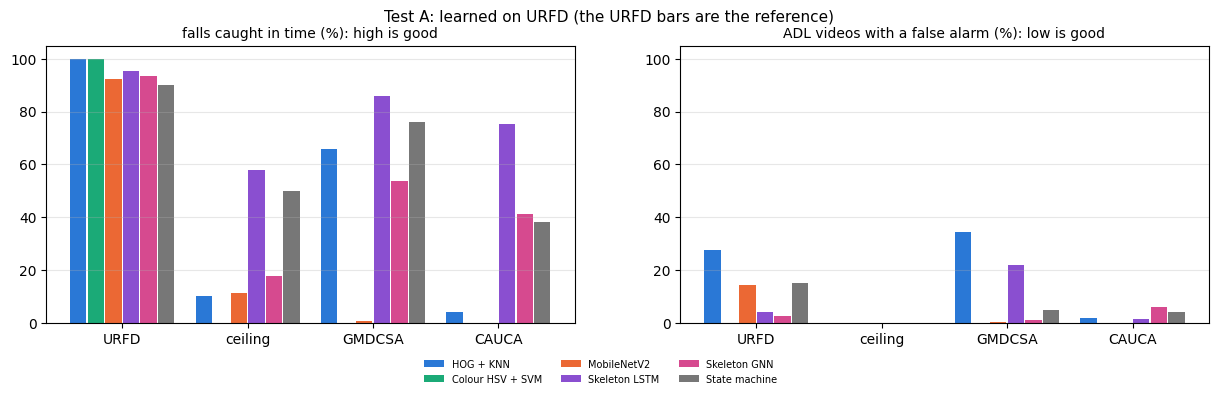

accuracy of the 3 starts (lowest-highest, %): {('MobileNetV2', 'GMDCSA'): (51, 51), ('MobileNetV2', 'CAUCA'): (50, 50), ('Skeleton LSTM', 'GMDCSA'): (80, 88), ('Skeleton LSTM', 'CAUCA'): (86, 93), ('Skeleton GNN', 'GMDCSA'): (71, 80), ('Skeleton GNN', 'CAUCA'): (56, 76)}


test set,URFD,GMDCSA,CAUCA,lost on GMDCSA,lost on CAUCA
method,,,,,
HOG + KNN,84.0,78.0,55.0,7.0,29.0
Colour HSV + SVM,100.0,51.0,50.0,49.0,50.0
MobileNetV2,89.0,51.0,50.0,38.0,39.0
Skeleton LSTM,96.0,84.0,90.0,12.0,6.0
Skeleton GNN,96.0,76.0,68.0,19.0,28.0
State machine,87.0,86.0,67.0,2.0,20.0


In [8]:
def points_table(combo_of):
    """falls in time (%) and false alarms (%) for each method and test set."""
    rows = []
    for d in SHORT:
        for m in EVERY:
            s = summary(ALL[m, combo_of(d)][0][d])
            rows.append({"test set": SHORT[d], "method": m, "lowest": 100 * s["lowest"], "highest": 100 * s["highest"], "falls": 100 * s["in time"] / s["falls"], "alarms": 100 * s["false alarms"] / s["ADLs"] if s["ADLs"] else np.nan, "accuracy": 100 * s["video accuracy"] if s["ADLs"] else np.nan})
    return pd.DataFrame(rows)
COLORS = dict(zip(EVERY, ["#2a78d6", "#1baa77", "#eb6834", "#8a4fd0", "#d64a8f", "#777777"]))
def bars(t, title):
    fig, axes = plt.subplots(1, 2, figsize=(15, 3.6)); order = [s for s in SHORT.values() if s in set(t["test set"])]
    for ax, col, label in [(axes[0], "falls", "falls caught in time (%): high is good"), (axes[1], "alarms", "ADL videos with a false alarm (%): low is good")]:
        for i, m in enumerate(EVERY):
            d = t[t.method == m].set_index("test set").loc[order]
            ax.bar(np.arange(len(order)) + (i - 2.5) * 0.14, d[col], 0.13, color=COLORS[m], label=m)
        ax.set_xticks(range(len(order))); ax.set_xticklabels(order); ax.set_title(label, fontsize=10); ax.set_ylim(0, 105); ax.grid(axis="y", alpha=0.3)
    axes[0].legend(fontsize=7, ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(1.05, -0.1)); fig.suptitle(title, fontsize=11); plt.show()
tA = points_table(lambda d: "URFD")
bars(tA, "Test A: learned on URFD (the URFD bars are the reference)")
acc = tA.pivot(index="method", columns="test set", values="accuracy").loc[EVERY, ["URFD", "GMDCSA", "CAUCA"]]
acc["lost on GMDCSA"], acc["lost on CAUCA"] = acc.URFD - acc.GMDCSA, acc.URFD - acc.CAUCA
print("accuracy of the 3 starts (lowest-highest, %):", {(m, d): tuple(tA[(tA.method == m) & (tA["test set"] == d)][["lowest", "highest"]].round(0).astype(int).iloc[0].tolist()) for m in METHODS if m in NETS for d in ["GMDCSA", "CAUCA"]})
acc.round(0)

💡 **Interpretation:** accuracy lost on GMDCSA / CAUCAFall: colour −49 / −50 points, MobileNetV2 −38 / −39, GNN −19 / −28, HOG −7 / −29, state machine −2 / −20, **LSTM −12 / −6**. Answering *no fall* everywhere gives 51 and 50%: colour and MobileNetV2 are at **chance**.
The 3 starts of the LSTM give 80-88% (GMDCSA) and 86-93% (CAUCAFall); the GNN changes much more (56-76% on CAUCAFall).

### Is it the score or the threshold?

Two things can fail on a new dataset:
- the **score** itself (falls do not get higher scores than daily activities);
- only the **threshold** (the order is good, but all the scores are higher or lower than in URFD).

The **AUC** of the highest score of each video answers the first one without any threshold: 1 = perfect order, **0.5 = chance**.
We also show the result with a threshold chosen **on the test set itself**: this is **cheating**, and only shows how much better the threshold could be.

In [9]:
def auc(score, names):
    return roc_auc_score([info.kind[v] == "fall" for v in names], [smooth(score, ROWS[v]).max() for v in names])
def cheat(score, names):                                                                 # the best video accuracy over all the thresholds
    top, fall = np.array([smooth(score, ROWS[v]).max() for v in names]), np.array([KIND[v] == "fall" for v in names])
    return max(np.mean((top > thr) == fall) for thr in THRESHOLDS)
def auc_table(combo_of):
    rows = {}
    for d in ["URFD cam0", "GMDCSA-24", "CAUCAFall"]:
        c = combo_of(d); n = names_of([d])
        for m in METHODS:
            rows.setdefault(m, {})[f"{SHORT[d]}: AUC"] = np.mean([auc(SCORES[m, c, s], n) for s in SEEDS[m]])
            rows[m][f"{SHORT[d]}: accuracy"] = summary(ALL[m, c][0][d])["video accuracy"]
            if d not in COMBOS[c]: rows[m][f"{SHORT[d]}: best threshold (cheating)"] = np.mean([cheat(SCORES[m, c, s], n) for s in SEEDS[m]])
    return pd.DataFrame(rows).T.round(2)
auc_table(lambda d: "URFD")

,URFD: AUC,URFD: accuracy,GMDCSA: AUC,GMDCSA: accuracy,GMDCSA: best threshold (cheating),CAUCA: AUC,CAUCA: accuracy,CAUCA: best threshold (cheating)
HOG + KNN,0.86,0.84,0.79,0.78,0.78,0.68,0.55,0.64
Colour HSV + SVM,1.00,1.00,0.81,0.51,0.74,0.44,0.50,0.51
MobileNetV2,0.98,0.89,0.71,0.51,0.68,0.57,0.50,0.58
Skeleton LSTM,0.99,0.96,0.92,0.84,0.87,0.95,0.90,0.92
Skeleton GNN,0.98,0.96,0.93,0.76,0.85,0.79,0.68,0.76


💡 **Interpretation:** for the LSTM the order of the videos stays good (AUC **0.92 and 0.95**), and even the best possible threshold adds only 2-3 points.
MobileNetV2 (0.71 and 0.57) and HOG (0.79 and 0.68) lose the order itself. Colour keeps some order on GMDCSA (0.81; a better threshold would give 0.74) but none on CAUCAFall (0.44).

### Check: is it the skeleton, or only the fact that somebody is found?

MediaPipe loses people more often in some moments. As in notebook 12, we train the same LSTM with **only the *found* flag** (all the positions set to 0), with the same protocol.

In [10]:
class FlagOnly(nn.Module):
    def __init__(self, n): super().__init__(); self.net = LSTM(n)
    def forward(self, w):
        w = w.clone(); w[..., :4] = 0; return self.net(w)
FLAG = "check: found flag only"
NETS[FLAG] = (FlagOnly, window_batch, 20, 1e-3, 128)
rows = {}
for d, c, test in [("GMDCSA-24", "URFD", "A"), ("CAUCAFall", "URFD", "A"), ("URFD cam0", "GMDCSA + CAUCA", "B"), ("GMDCSA-24", "URFD + CAUCA", "B"), ("CAUCAFall", "URFD + GMDCSA", "B")]:
    n = names_of([d]); flag = [run(FLAG, c, s, tag="") for s in range(3)]
    tables = results_of(c, flag)[0][d]
    rows[f"{test}: {SHORT[d]}"] = {"flag only: AUC": np.mean([auc(f, n) for f in flag]), "LSTM: AUC": np.mean([auc(SCORES["Skeleton LSTM", c, s], n) for s in range(3)]),
                                   "flag only: accuracy": summary(tables)["video accuracy"], "LSTM: accuracy": summary(ALL["Skeleton LSTM", c][0][d])["video accuracy"]}
pd.DataFrame(rows).T.round(2)

,flag only: AUC,LSTM: AUC,flag only: accuracy,LSTM: accuracy
A: GMDCSA,0.62,0.92,0.54,0.84
A: CAUCA,0.51,0.95,0.51,0.90
B: URFD,0.54,1.00,0.59,0.88
B: GMDCSA,0.60,0.96,0.54,0.86
B: CAUCA,0.53,0.86,0.54,0.82


💡 **Interpretation:** the *found* flag alone is at **chance** (AUC 0.51-0.62, accuracy 0.51-0.59), far from the LSTM (0.86-1.00 and 0.82-0.90).
So the LSTM really uses the positions of the joints, also in the new datasets.

### The postures of our notebooks, "exactly as now"

Until now, HOG, colour, MobileNetV2 and the LSTM were trained on **3 postures** (*not lying / falling / lying*). Here we do the same on URFD and use *P(falling) + P(lying)* as the fall score. Is it better or worse than learning *fall / no fall* directly?

In [11]:
lab = pd.concat([pd.read_csv(Path("..") / "data" / "raw" / "urfd" / "labels" / f"urfall-cam0-{k}.csv", header=None, usecols=[0, 1, 2]) for k in ["falls", "adls"]])
lab.columns = ["v", "f", "l"]; lab = lab.assign(video="cam0-" + lab.v, index=lab.f - 1)[["video", "index", "l"]]
posture = frames[["video", "index"]].merge(lab, on=["video", "index"], how="left").l.fillna(-2).astype(int).to_numpy(copy=True) + 1     # 0 not lying, 1 falling, 2 lying, -1 = no label
POST = ["HOG + KNN", "Colour HSV + SVM", "MobileNetV2", "Skeleton LSTM"]
for m in POST:
    scores = [run(m, "URFD", s, target=posture, n=3, tag="_postures") for s in SEEDS[m]]
    ALL[m + " (postures)", "URFD"] = results_of("URFD", scores)
pd.concat({w: pd.DataFrame({m: {SHORT[d]: (lambda s: f"{s['in time']:.0f}/{s['falls']:.0f} falls, {s['false alarms']:.0f}/{s['ADLs']:.0f} alarms" if s["ADLs"] else f"{s['in time']:.0f}/{s['falls']:.0f} falls")(summary(ALL[m + w, "URFD"][0][d])) for d in SHORT}
                           for m in POST}).T for w in ["", " (postures)"]}).rename(index={"": "fall / no fall", " (postures)": "3 postures"})

URFD      ceiling  \
fall / no fall HOG + KNN         30/30 falls, 11/40 alarms   3/30 falls   
               Colour HSV + SVM   30/30 falls, 0/40 alarms   0/30 falls   
               MobileNetV2        28/30 falls, 6/40 alarms   3/30 falls   
               Skeleton LSTM      29/30 falls, 2/40 alarms  17/30 falls   
3 postures     HOG + KNN         30/30 falls, 27/40 alarms   4/30 falls   
               Colour HSV + SVM   29/30 falls, 2/40 alarms   0/30 falls   
               MobileNetV2        27/30 falls, 2/40 alarms   2/30 falls   
               Skeleton LSTM     27/30 falls, 15/40 alarms  12/30 falls   

                                                    GMDCSA  \
fall / no fall HOG + KNN         52/79 falls, 28/81 alarms   
               Colour HSV + SVM    0/79 falls, 0/81 alarms   
               MobileNetV2         1/79 falls, 0/81 alarms   
               Skeleton LSTM     68/79 falls, 18/81 alarms   
3 postures     HOG + KNN         50/79 falls, 51/81 alarms   
               Colour HSV + SVM    3/79 falls, 0/81 alarms   
               MobileNetV2       11/79 falls, 10/81 alarms   
               Skeleton LSTM     74/79 falls, 45/81 alarms   

                                                     CAUCA  
fall / no fall HOG + KNN           2/50 falls, 1/50 alarms  
               Colour HSV + SVM    0/50 falls, 0/50 alarms  
               MobileNetV2         0/50 falls, 0/50 alarms  
               Skeleton LSTM      38/50 falls, 1/50 alarms  
3 postures     HOG + KNN         16/50 falls, 24/50 alarms  
               Colour HSV + SVM    0/50 falls, 0/50 alarms  
               MobileNetV2         0/50 falls, 0/50 alarms  
               Skeleton LSTM     44/50 falls, 16/50 alarms

💡 **Interpretation:** with 3 postures the LSTM catches a few more falls (74 of 79, 44 of 50), but with far more false alarms (45 of 81 and 16 of 50, against 18 and 1): lying down on a bed also gives *lying*.
MobileNetV2 and colour stay near chance either way (0.50-0.54). *Fall / no fall* is the better answer to learn for the LSTM (0.84 and 0.90, against 0.71 and 0.82).

## Step 6 — Test B: learn on two datasets, test on the third

Does **more variety** in the training (other cameras, other rooms) help on a dataset never seen? The threshold is chosen on the two training datasets.

In [12]:
B = {"URFD cam0": "GMDCSA + CAUCA", "URFD cam1": "GMDCSA + CAUCA", "GMDCSA-24": "URFD + CAUCA", "CAUCAFall": "URFD + GMDCSA"}
show_table([(m, B[d], d) for d in SHORT for m in EVERY])

video accuracy falls in time false alarms  \
test set method                                                       
URFD     HOG + KNN                  0.60     18.0 / 30    16.0 / 40   
         Colour HSV + SVM           0.67      7.0 / 30     0.0 / 40   
         MobileNetV2                0.77     21.3 / 30     7.7 / 40   
         Skeleton LSTM              0.88     30.0 / 30     8.3 / 40   
         Skeleton GNN               0.84     29.3 / 30    10.3 / 40   
         State machine              0.83     30.0 / 30    12.0 / 40   
ceiling  HOG + KNN                     -      3.0 / 30            -   
         Colour HSV + SVM              -      0.0 / 30            -   
         MobileNetV2                   -      1.7 / 30            -   
         Skeleton LSTM                 -     21.0 / 30            -   
         Skeleton GNN                  -     16.3 / 30            -   
         State machine                 -     22.0 / 30            -   
GMDCSA   HOG + KNN                  0.64     50.0 / 79    49.0 / 81   
         Colour HSV + SVM           0.51      0.0 / 79     0.0 / 81   
         MobileNetV2                0.61     37.3 / 79    25.0 / 81   
         Skeleton LSTM              0.86     71.7 / 79    17.3 / 81   
         Skeleton GNN               0.85     66.3 / 79    14.3 / 81   
         State machine              0.84     67.0 / 79    13.0 / 81   
CAUCA    HOG + KNN                  0.54      3.0 / 50     1.0 / 50   
         Colour HSV + SVM           0.55      3.0 / 50     1.0 / 50   
         MobileNetV2                0.66     14.0 / 50     4.3 / 50   
         Skeleton LSTM              0.82     39.7 / 50     8.7 / 50   
         Skeleton GNN               0.69     29.3 / 50    10.7 / 50   
         State machine              0.68     20.0 / 50     3.0 / 50   

                           early alarms  latency (s)  
test set method                                       
URFD     HOG + KNN                  0.0         1.08  
         Colour HSV + SVM           0.0         0.90  
         MobileNetV2                0.0         0.83  
         Skeleton LSTM              0.0         0.66  
         Skeleton GNN               0.0         0.63  
         State machine              0.0         1.03  
ceiling  HOG + KNN                  6.0         0.50  
         Colour HSV + SVM           2.0          NaN  
         MobileNetV2                0.3         0.50  
         Skeleton LSTM              3.3         0.77  
         Skeleton GNN               3.0         0.75  
         State machine              3.0         1.00  
GMDCSA   HOG + KNN                 20.0         1.05  
         Colour HSV + SVM           0.0          NaN  
         MobileNetV2                3.0         0.99  
         Skeleton LSTM              1.7         1.04  
         Skeleton GNN               1.7         1.04  
         State machine              0.0         1.44  
CAUCA    HOG + KNN                  0.0         2.55  
         Colour HSV + SVM           2.0         1.60  
         MobileNetV2                1.7         1.52  
         Skeleton LSTM              0.7         1.07  
         Skeleton GNN               0.0         0.83  
         State machine              1.0         1.75

💡 **Interpretation:** learned on two datasets and tested on the third, the **LSTM is first on all three**: 0.88 (URFD, 30 of 30 falls), 0.86 (GMDCSA) and 0.82 (CAUCAFall). The GNN and the rules follow (0.68-0.85); MobileNetV2 gets 0.61-0.77, HOG and colour 0.51-0.67.
From the ceiling, the best are the state machine (22 of 30) and the LSTM (21 of 30): still the hardest camera, and here false alarms cannot be measured.

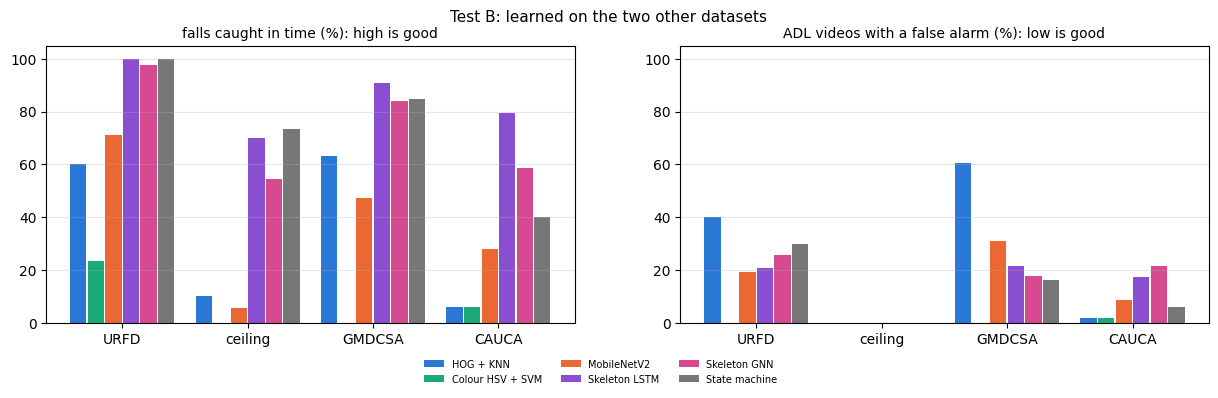

accuracy of the 3 starts in test B (lowest-highest, %): {('MobileNetV2', 'URFD'): (74, 80), ('MobileNetV2', 'GMDCSA'): (57, 65), ('MobileNetV2', 'CAUCA'): (56, 73), ('Skeleton LSTM', 'URFD'): (87, 90), ('Skeleton LSTM', 'GMDCSA'): (84, 91), ('Skeleton LSTM', 'CAUCA'): (78, 85), ('Skeleton GNN', 'URFD'): (74, 93), ('Skeleton GNN', 'GMDCSA'): (79, 89), ('Skeleton GNN', 'CAUCA'): (57, 76)}


accuracy                                 \
test set                GMDCSA         CAUCA           GMDCSA   
test             A (URFD only) A (URFD only) B (two datasets)   
method                                                          
HOG + KNN                   78            55               64   
Colour HSV + SVM            51            50               51   
MobileNetV2                 51            50               61   
Skeleton LSTM               84            90               86   
Skeleton GNN                76            68               85   
State machine               86            67               84   

                                          falls                \
test set                    CAUCA        GMDCSA         CAUCA   
test             B (two datasets) A (URFD only) A (URFD only)   
method                                                          
HOG + KNN                      54            66             4   
Colour HSV + SVM               55             0             0   
MobileNetV2                    66             1             0   
Skeleton LSTM                  82            86            75   
Skeleton GNN                   69            54            41   
State machine                  68            76            38   

                                                          alarms  \
test set                   GMDCSA            CAUCA        GMDCSA   
test             B (two datasets) B (two datasets) A (URFD only)   
method                                                             
HOG + KNN                      63                6            35   
Colour HSV + SVM                0                6             0   
MobileNetV2                    47               28             0   
Skeleton LSTM                  91               79            22   
Skeleton GNN                   84               59             1   
State machine                  85               40             5   

                                                                  
test set                 CAUCA           GMDCSA            CAUCA  
test             A (URFD only) B (two datasets) B (two datasets)  
method                                                            
HOG + KNN                    2               60                2  
Colour HSV + SVM             0                0                2  
MobileNetV2                  0               31                9  
Skeleton LSTM                1               21               17  
Skeleton GNN                 6               18               21  
State machine                4               16                6

In [13]:
tB = points_table(lambda d: B[d])
bars(tB, "Test B: learned on the two other datasets")
both = pd.concat({"A (URFD only)": tA, "B (two datasets)": tB}).reset_index(level=0, names="test")
print("accuracy of the 3 starts in test B (lowest-highest, %):", {(m, d): tuple(tB[(tB.method == m) & (tB["test set"] == d)][["lowest", "highest"]].round(0).astype(int).iloc[0].tolist()) for m in METHODS if m in NETS for d in ["URFD", "GMDCSA", "CAUCA"]})
both[both["test set"].isin(["GMDCSA", "CAUCA"])].pivot_table(index="method", columns=["test set", "test"], values=["accuracy", "falls", "alarms"], sort=False).loc[EVERY].round(0).astype(int)

💡 **Interpretation:** more variety helps MobileNetV2 (51 to 61% on GMDCSA, 50 to 66% on CAUCAFall) and the GNN on GMDCSA (76 to 85%).
For the LSTM it changes little on GMDCSA (84 to 86%, the starts overlap) and it is **worse on CAUCAFall** (90 to 82%): false alarms go from 1 to 17%. We did not find out why.

In [14]:
auc_table(lambda d: B[d])

,URFD: AUC,URFD: accuracy,URFD: best threshold (cheating),GMDCSA: AUC,GMDCSA: accuracy,GMDCSA: best threshold (cheating),CAUCA: AUC,CAUCA: accuracy,CAUCA: best threshold (cheating)
HOG + KNN,0.66,0.60,0.61,0.66,0.64,0.64,0.75,0.54,0.69
Colour HSV + SVM,0.91,0.67,0.84,0.77,0.51,0.72,0.64,0.55,0.60
MobileNetV2,0.83,0.77,0.81,0.67,0.61,0.64,0.84,0.66,0.81
Skeleton LSTM,1.00,0.88,0.97,0.96,0.86,0.90,0.86,0.82,0.86
Skeleton GNN,0.97,0.84,0.94,0.94,0.85,0.88,0.72,0.69,0.74


💡 **Interpretation:** the LSTM orders the URFD videos perfectly (AUC **1.00**), so its 0.88 comes from the **threshold** (0.97 with the best one). On GMDCSA the AUC is 0.96, on CAUCAFall 0.86.
MobileNetV2 orders CAUCAFall well now (0.84) but is poor on GMDCSA (0.67).

### And if the dataset is in the training (other people)?

In test B, the folds by person also give a score for the training datasets themselves: **same camera and room, but new people**. Compared with the *never seen* column, this shows how much of the drop comes from the **new place** and the new camera.
CAUCAFall has only one room, so its "new people" are in a room that the model knows.

In [15]:
rows = {}
for m in EVERY:
    for d, c in [("GMDCSA-24", "URFD + GMDCSA"), ("CAUCAFall", "URFD + CAUCA")]:
        rows.setdefault(m, {})[f"{SHORT[d]}: known place, new people"] = summary(ALL[m, c][0][d])["video accuracy"]
        rows[m][f"{SHORT[d]}: never seen (test B)"] = summary(ALL[m, B[d]][0][d])["video accuracy"]
pd.DataFrame(rows).T.round(2)

,"GMDCSA: known place, new people",GMDCSA: never seen (test B),"CAUCA: known place, new people",CAUCA: never seen (test B)
HOG + KNN,0.65,0.64,0.77,0.54
Colour HSV + SVM,0.66,0.51,0.69,0.55
MobileNetV2,0.62,0.61,0.90,0.66
Skeleton LSTM,0.91,0.86,0.94,0.82
Skeleton GNN,0.86,0.85,0.80,0.69
State machine,0.86,0.84,0.76,0.68


💡 **Interpretation:** a **known room** helps the image methods most on CAUCAFall: MobileNetV2 0.90 with new people in the known room, but **0.66** when the dataset was never seen (HOG 0.77 to 0.54, LSTM 0.94 to 0.82).
On GMDCSA the LSTM loses little (0.91 to 0.86), and the image methods are poor even in known rooms (0.62-0.66).

### Which method would we choose without looking at the test?

In a real project the test dataset is not available. So we look only at the **training datasets** (new people, the reference scores), choose the best method there, and see what it does on the datasets **never seen**.

In [16]:
SIDE = ["URFD cam0", "GMDCSA-24", "CAUCAFall"]
rows = {}
for c in COMBOS:
    for m in EVERY:
        acc_of = lambda sets: np.mean([summary(ALL[m, c][0][d])["video accuracy"] for d in sets])
        rows.setdefault(m, {})[f"{c} | new people"] = acc_of(COMBOS[c]); rows[m][f"{c} | never seen"] = acc_of([d for d in SIDE if d not in COMBOS[c]])
choice = pd.DataFrame(rows).T
for c in COMBOS:
    best_m = choice[f"{c} | new people"].idxmax(); print(f"trained on {c}: we would choose {best_m} ({choice.loc[best_m, f'{c} | new people']:.2f}) -> {choice.loc[best_m, f'{c} | never seen']:.2f} on the datasets never seen")
choice.round(2)

trained on URFD: we would choose Colour HSV + SVM (1.00) -> 0.50 on the datasets never seen
trained on GMDCSA + CAUCA: we would choose Skeleton LSTM (0.90) -> 0.88 on the datasets never seen
trained on URFD + CAUCA: we would choose Skeleton LSTM (0.94) -> 0.86 on the datasets never seen
trained on URFD + GMDCSA: we would choose Skeleton LSTM (0.93) -> 0.82 on the datasets never seen


,URFD | new people,URFD | never seen,GMDCSA + CAUCA | new people,GMDCSA + CAUCA | never seen,URFD + CAUCA | new people,URFD + CAUCA | never seen,URFD + GMDCSA | new people,URFD + GMDCSA | never seen
HOG + KNN,0.84,0.66,0.67,0.60,0.76,0.64,0.78,0.54
Colour HSV + SVM,1.00,0.50,0.68,0.67,0.84,0.51,0.83,0.55
MobileNetV2,0.89,0.50,0.80,0.77,0.86,0.61,0.73,0.66
Skeleton LSTM,0.96,0.87,0.90,0.88,0.94,0.86,0.93,0.82
Skeleton GNN,0.96,0.72,0.85,0.84,0.85,0.85,0.88,0.69
State machine,0.87,0.76,0.77,0.83,0.81,0.84,0.89,0.68


💡 **Interpretation:** with URFD alone we would choose **colour + SVM (1.00)**, which is **at chance (0.50)** on new datasets. With two training datasets we would choose the **LSTM every time**, and it keeps 0.82 to 0.88.
So a benchmark with one dataset can choose the worst method.

## Step 7 — Where are the mistakes?

We look at the method with the best accuracy **averaged over the never-seen datasets of test B** (URFD, GMDCSA, CAUCAFall), on the GMDCSA and CAUCAFall results of test B.

In [17]:
mean_acc = tB[tB["test set"].isin(["URFD", "GMDCSA", "CAUCA"])].groupby("method").accuracy.mean().loc[EVERY].round(1)
print("mean accuracy on a never-seen dataset (test B):", mean_acc.to_dict())
print("mean accuracy on GMDCSA and CAUCA in test A:", tA[tA["test set"].isin(["GMDCSA", "CAUCA"])].groupby("method").accuracy.mean().loc[EVERY].round(1).to_dict())
best = mean_acc.idxmax(); print("method studied:", best, "\n")
r = pd.concat([pd.concat(ALL[best, B[d]][0][d]) for d in ["GMDCSA-24", "CAUCAFall"]]).merge(videos[["video", "activity", "light", "person"]], on="video")
adl, falls = r[~r.fall], r[r.fall]
c = adl[adl.dataset == "CAUCAFall"].groupby("activity").alarm.mean().round(2); print("CAUCAFall, share of ADLs with a false alarm:", c.to_dict())
g = adl[adl.dataset == "GMDCSA-24"]
print("GMDCSA-24, share of ADLs with a false alarm, by activity in the video:", {k: f"{g[g.activity.str.contains(k)].alarm.mean():.2f} ({g[g.activity.str.contains(k)].video.nunique()} videos)" for k in ["Sleeping", "Sitting", "Walking", "Standing", "Exercising", "Reading"]})
print("CAUCAFall, share of falls in time:", falls[falls.dataset == "CAUCAFall"].groupby("activity").in_time.mean().round(2).to_dict())
print("GMDCSA-24, share of falls in time, per person:", falls[falls.dataset == "GMDCSA-24"].groupby("person").in_time.mean().round(2).to_dict())
dark = falls[falls.dataset == "GMDCSA-24"].assign(dark=lambda q: np.where(q.light.str.contains("night|off", case=False), "night or light off", "day, light on"))
print("GMDCSA-24, share of falls in time, per light:", dark.groupby("dark").in_time.mean().round(2).to_dict())
seen = frames[(frames.t >= frames.start) & (frames.t <= frames.start + 2)].groupby("video").skeleton_found.mean()
falls = falls.assign(skeleton=pd.cut(falls.video.map(seen), [-0.01, 0.5, 0.9, 1.0], labels=["found < 50%", "50-90%", "> 90%"]))
print("\nfalls in time, by how often the skeleton is found in the 2 s after the start:")
falls.groupby(["dataset", "skeleton"], observed=True).in_time.agg(["mean", "size"]).round(2).rename(columns={"mean": "share in time", "size": "falls × starts"})

mean accuracy on a never-seen dataset (test B): {'HOG + KNN': 59.5, 'Colour HSV + SVM': 57.6, 'MobileNetV2': 67.8, 'Skeleton LSTM': 85.5, 'Skeleton GNN': 79.2, 'State machine': 78.4}
mean accuracy on GMDCSA and CAUCA in test A: {'HOG + KNN': 66.2, 'Colour HSV + SVM': 50.3, 'MobileNetV2': 50.4, 'Skeleton LSTM': 86.6, 'Skeleton GNN': 72.1, 'State machine': 76.3}
method studied: Skeleton LSTM 

CAUCAFall, share of ADLs with a false alarm: {'Hop': 0.27, 'Kneel': 0.33, 'Pick up object': 0.07, 'Sit down': 0.13, 'Walk': 0.07}
GMDCSA-24, share of ADLs with a false alarm, by activity in the video: {'Sleeping': '0.55 (14 videos)', 'Sitting': '0.18 (55 videos)', 'Walking': '0.19 (34 videos)', 'Standing': '0.16 (29 videos)', 'Exercising': '0.39 (11 videos)', 'Reading': '0.15 (16 videos)'}
CAUCAFall, share of falls in time: {'Fall backwards': 0.77, 'Fall forward': 0.87, 'Fall left': 0.83, 'Fall right': 1.0, 'Fall sitting': 0.5}
GMDCSA-24, share of falls in time, per person: {'subject 1': 0.83, 'sub

share in time  falls × starts
dataset   skeleton                                  
CAUCAFall found < 50%           0.58              12
          50-90%                0.97              36
          > 90%                 0.75             102
GMDCSA-24 found < 50%           0.50               6
          50-90%                0.78              27
          > 90%                 0.94             204

💡 **Interpretation:** false alarms of the LSTM: *sleeping* (0.55 of the 14 videos), *exercising* (0.39), *kneel* (0.33) and *hop* (0.27): the person goes down or moves fast. Missed falls: *fall sitting* (only 0.50 in time) and falls in the dark (0.80 against 0.94 in light).
When MediaPipe finds the person less than half of the time, only 0.50-0.58 are caught (few cases); above that there is no clear link in CAUCAFall.

## Step 8 — Size and speed

Milliseconds **per image**, one image at a time, on this laptop: first *find the person* (box or skeleton), then the method. The CNN, LSTM and GNN run on the GPU; the rest on the processor.

In [18]:
def ms(f, n=60):
    f(); f(); t = time.perf_counter()
    for _ in range(n): f()
    if device == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t) / n * 1000
import mediapipe as mp
from mediapipe.tasks.python import vision, BaseOptions
image = cv2.imread(str(sorted((Path("..") / "data" / "raw" / "urfd" / "rgb" / "fall-01").rglob("*.png"))[40])); bg = cv2.GaussianBlur(image, (5, 5), 0); kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
def find_box():
    m = (cv2.absdiff(cv2.GaussianBlur(image, (5, 5), 0), bg).max(axis=2) > 25).astype(np.uint8) * 255
    m = cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_OPEN, kernel), cv2.MORPH_CLOSE, kernel, iterations=2); cv2.findContours(m, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
pose = vision.PoseLandmarker.create_from_options(vision.PoseLandmarkerOptions(base_options=BaseOptions(model_asset_path=str(Path("..") / "models" / "pose_landmarker_full.task")), running_mode=vision.RunningMode.VIDEO, num_poses=1))
clock = [0]
def find_pose(): clock[0] += 33; pose.detect_for_video(mp.Image(image_format=mp.ImageFormat.SRGB, data=cv2.cvtColor(image, cv2.COLOR_BGR2RGB)), clock[0])
box_ms, pose_ms = ms(find_box), ms(find_pose); pose.close()
rows = train_rows(np.isin(dataset, COMBOS["URFD"]), y); rb = rows[boxed[rows]]
crop = np.load(NEW / "boxes" / "cam0-fall-01.npz")["crops64"][10]
knn, svm = KNeighborsClassifier(5).fit(HOG[rb], y[rb]), SVC(kernel="rbf", class_weight="balanced").fit(COLOUR[rb], y[rb])
one = torch.tensor([int(rb[0])], device=device)
cost = [{"method": "HOG + KNN", "find the person (ms)": box_ms, "method (ms)": ms(lambda: knn.predict_proba(hog_of(crop)[None].astype(np.float32))), "size (MB)": len(pickle.dumps(knn)) / 1e6},
        {"method": "Colour HSV + SVM", "find the person (ms)": box_ms, "method (ms)": ms(lambda: svm.decision_function(hsv_grid(crop)[None])), "size (MB)": len(pickle.dumps(svm)) / 1e6}]
for name in [m for m in METHODS if m in NETS]:
    make, batch = NETS[name][:2]
    net = make(2).to(device).eval(); b = io.BytesIO(); torch.save(net.state_dict(), b)
    with torch.no_grad(): cost.append({"method": name, "find the person (ms)": box_ms if name in IMAGE else pose_ms, "method (ms)": ms(lambda: net(batch(one, False)).softmax(1).cpu()), "size (MB)": b.tell() / 1e6})
cost.append({"method": "State machine", "find the person (ms)": pose_ms, "method (ms)": ms(lambda: machine(SIG["cam0-fall-01"], 0.6), 30) / len(SIG["cam0-fall-01"][0]), "size (MB)": 0})
cost = pd.DataFrame(cost).set_index("method"); cost["total (ms)"] = cost["find the person (ms)"] + cost["method (ms)"]
print("MediaPipe model:", round((Path("..") / "models" / "pose_landmarker_full.task").stat().st_size / 1e6, 1), "MB (added for the skeleton methods and the state machine)")
cost.round(2)

MediaPipe model: 9.4 MB (added for the skeleton methods and the state machine)


,find the person (ms),method (ms),size (MB),total (ms)
method,,,,
HOG + KNN,8.61,18.06,2.55,26.66
Colour HSV + SVM,8.61,0.74,3.23,9.35
MobileNetV2,8.61,9.68,9.15,18.28
Skeleton LSTM,31.13,0.85,0.12,31.98
Skeleton GNN,31.13,2.30,0.28,33.43
State machine,31.13,0.00,0.00,31.13


💡 **Interpretation:** the LSTM needs **32 ms per image** (31 for MediaPipe), so about 31 images per second on this laptop, and only 0.12 MB + 9.4 MB for MediaPipe. Colour + SVM is the fastest (9 ms).
HOG + KNN is slow (27 ms) because KNN compares every image with all the training images.

## Step 9 — The marks with the official onsets (for the common table with Adam)

Same alarms, same thresholds: only the moment called "onset" changes. Video accuracy and ADL false alarms do not depend on it.

In [19]:
rows = []
for test, pairs in {"A": [("URFD", d) for d in list(SHORT)[1:]], "B": [(B[d], d) for d in ["URFD cam0", "GMDCSA-24", "CAUCAFall"]]}.items():
    for c, d in pairs:
        for m in EVERY:
            s = summary(ALL[m, c][0][d]); rows.append({"test": test, "test set": SHORT[d], "method": m, "aligned": s["in time"], "official": s["in time (official onset)"], "Adam's code": s["in time (Adam's code)"],
                                                       "early, aligned": s["early alarms"], "early, official": s["early alarms (official onset)"], "falls": s["falls"]})
official = pd.DataFrame(rows).round(1)
official[official.method.isin(["HOG + KNN", "MobileNetV2", "Skeleton LSTM", "State machine"])].set_index(["test", "test set", "method"])

aligned  official  Adam's code  early, aligned  \
test test set method                                                          
A    ceiling  HOG + KNN          3.0       3.0          6.0            10.0   
              MobileNetV2        3.3       3.3          3.3             0.3   
              Skeleton LSTM     17.3      17.3         18.0             2.7   
              State machine     15.0      15.0         15.0             3.0   
     GMDCSA   HOG + KNN         52.0      52.0         64.0            18.0   
              MobileNetV2        0.7       0.7          0.7             0.0   
              Skeleton LSTM     68.0      68.0         69.3             1.0   
              State machine     60.0      60.0         60.0             0.0   
     CAUCA    HOG + KNN          2.0       3.0          3.0             1.0   
              MobileNetV2        0.0       0.0          0.0             0.0   
              Skeleton LSTM     37.7      21.3         23.7             0.7   
              State machine     19.0      15.0         15.0             0.0   
B    URFD     HOG + KNN         18.0      18.0         18.0             0.0   
              MobileNetV2       21.3      21.3         21.3             0.0   
              Skeleton LSTM     30.0      30.0         30.0             0.0   
              State machine     30.0      30.0         30.0             0.0   
     GMDCSA   HOG + KNN         50.0      46.0         67.0            20.0   
              MobileNetV2       37.3      36.7         38.0             3.0   
              Skeleton LSTM     71.7      70.0         72.0             1.7   
              State machine     67.0      67.0         67.0             0.0   
     CAUCA    HOG + KNN          3.0       2.0          2.0             0.0   
              MobileNetV2       14.0       8.7         13.7             1.7   
              Skeleton LSTM     39.7      13.0         18.0             0.7   
              State machine     20.0      15.0         15.0             1.0   

                             early, official  falls  
test test set method                                 
A    ceiling  HOG + KNN                 10.0   30.0  
              MobileNetV2                0.3   30.0  
              Skeleton LSTM              2.7   30.0  
              State machine              3.0   30.0  
     GMDCSA   HOG + KNN                 18.0   79.0  
              MobileNetV2                0.0   79.0  
              Skeleton LSTM              1.7   79.0  
              State machine              0.0   79.0  
     CAUCA    HOG + KNN                  1.0   50.0  
              MobileNetV2                0.0   50.0  
              Skeleton LSTM             18.3   50.0  
              State machine              4.0   50.0  
B    URFD     HOG + KNN                  0.0   30.0  
              MobileNetV2                0.0   30.0  
              Skeleton LSTM              0.0   30.0  
              State machine              0.0   30.0  
     GMDCSA   HOG + KNN                 24.0   79.0  
              MobileNetV2                3.7   79.0  
              Skeleton LSTM              3.3   79.0  
              State machine              0.0   79.0  
     CAUCA    HOG + KNN                  1.0   50.0  
              MobileNetV2                7.7   50.0  
              Skeleton LSTM             27.7   50.0  
              State machine              6.0   50.0

💡 **Interpretation:** with the **official onsets**, only CAUCAFall changes a lot: the LSTM goes from 37.7 to **21.3** falls in time (A) and from 39.7 to **13.0** (B), because 18 to 28 of its alarms come **during** the fall, before the official onset (notebook 13a), and are called early.
The other test sets change by at most 4 falls. The common table with Adam must use the same definition for everybody.

## Step 10 — Save for the final table

One row per (method, test set), with the marks agreed with Adam, in `results/cross_dataset_mahran.csv`.

In [20]:
out = []
for (m, c), (tables, thr) in ALL.items():
    for d, tab in tables.items():
        s = summary(tab); known = d in COMBOS[c]
        test = "reference (training dataset, new people)" if known else "A" if c == "URFD" else "B" if B[d] == c else "other"
        base = m.replace(" (postures)", "")
        out.append({"test": test, "method": m, "trained on": c, "test set": d, "starts": len(tab), "falls": s["falls"], "ADLs": s["ADLs"], "video accuracy": s["video accuracy"] if s["ADLs"] else np.nan,
                    "accuracy lowest": s["lowest"] if s["ADLs"] else np.nan, "accuracy highest": s["highest"] if s["ADLs"] else np.nan, "falls in time": s["in time"], "falls in time (official onset)": s["in time (official onset)"], "falls in time (Adam's code)": s["in time (Adam's code)"],
                    "ADLs with a false alarm": s["false alarms"], "falls with an early alarm": s["early alarms"], "falls with an early alarm (official onset)": s["early alarms (official onset)"], "median latency (s)": s["latency"], "thresholds": " ".join(f"{float(t):.3g}" for t in thr),
                    "size (MB)": cost["size (MB)"][base], "ms per image": cost["total (ms)"][base]})
out = pd.DataFrame(out).round(3)
out.to_csv(RESULTS / "cross_dataset_mahran.csv", index=False)
print(out.shape, out.test.value_counts().to_dict())
out[out.test.isin(["A", "B"])].groupby(["test", "test set"])["video accuracy"].max()

(112, 20) {'reference (training dataset, new people)': 46, 'A': 30, 'B': 24, 'other': 12}


test  test set 
A     CAUCAFall    0.897
      GMDCSA-24    0.856
      URFD cam1      NaN
B     CAUCAFall    0.820
      GMDCSA-24    0.865
      URFD cam0    0.881
      URFD cam1      NaN
Name: video accuracy, dtype: float64

💡 **Interpretation:** 112 rows (method × training × test set), saved in `results/cross_dataset_mahran.csv`, in git, for the common table. The columns give the marks with both onsets, the spread of the starts, the size and the speed.

## What we learned

**Do our detectors still work with a camera, a room and people never seen?** It depends on what they look at:

| Method | Reference: URFD, new people | Test A: GMDCSA / CAUCAFall | Test B: URFD / GMDCSA / CAUCAFall | Ceiling, falls in time (A / B) |
|---|---|---|---|---|
| **Skeleton LSTM** | 0.96 | **0.84 / 0.90** | **0.88 / 0.86 / 0.82** | 17.3 / 21.0 of 30 |
| State machine (rules) | 0.87 | 0.86 / 0.67 | 0.83 / 0.84 / 0.68 | 15 / 22 of 30 |
| Skeleton GNN | 0.96 | 0.76 / 0.68 | 0.84 / 0.85 / 0.69 | 5.3 / 16.3 of 30 |
| HOG + KNN | 0.84 | 0.78 / 0.55 | 0.60 / 0.64 / 0.54 | 3 / 3 of 30 |
| MobileNetV2 | 0.89 | 0.51 / 0.50 | 0.77 / 0.61 / 0.66 | 3.3 / 1.7 of 30 |
| Colour HSV + SVM | **1.00** | 0.51 / 0.50 | 0.67 / 0.51 / 0.55 | 0 / 0 of 30 |

(video accuracy; answering *no fall* everywhere gives 0.57 on URFD, 0.51 on GMDCSA and 0.50 on CAUCAFall)

1. **Scores on one dataset are misleading.** The best method on URFD, colour + SVM (1.00), is at chance elsewhere: choosing on URFD alone would choose the worst method.
2. **The skeleton LSTM is the best choice**: first or second in all the tests, 0.82-0.90 on datasets never seen, and it is also the one we would choose on the two training datasets of test B. It is small (0.12 MB + MediaPipe, 32 ms per image).
3. **Simple rules are a serious competitor** on side cameras (GMDCSA 0.84-0.86) and the best from the ceiling in test B, but weak on the high corner camera of CAUCAFall (0.67-0.68).
4. **Image methods depend on the place**: MobileNetV2 gets 0.90 on CAUCAFall when the room is known, 0.66 when it is not.
5. **More data helps, but not always:** test B improves MobileNetV2 and the GNN, changes little for the LSTM on GMDCSA, and lowers it on CAUCAFall (90% to 82%).
6. **The ceiling camera stays hard**: at best 22 of 30 falls in time.

**Limits:** the start of a fall is not the same moment in each dataset (we aligned it with a fixed shift; with the official onsets CAUCAFall falls in time drop a lot); each dataset has few rooms (GMDCSA three, CAUCAFall one), so *never seen* means one to three rooms; the box of the image methods uses the median of the whole video (not real-time); a threshold is one number chosen on few videos; the ceiling has no ADL, so its false alarms are unknown.